# Visualizations of the abiotic plant simulation


## Importing Files and Packages

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Supports running from the project root or visualizations folder.
project_folder = (
    Path.cwd().parent
    if Path.cwd().name == "visualizations"
    else Path.cwd()
)

simulation_file = (
    project_folder / "data/simulations/simulation_001.npz"
)

## Loading the results

In [4]:
with np.load(simulation_file, allow_pickle=False) as data:
    final_plants = data["final_plants"]
    abiotic_effects = data["abiotic_effects"]
    years = int(data["years"])

print("Plants per species:", final_plants.sum(axis=(1, 2)))
print("Abiotic effects [germination, competition, reproduction]:",
      abiotic_effects)

Plants per species: [1437 4287 3584 3280]
Abiotic effects [germination, competition, reproduction]: [ True  True  True]


## Plotting the final community

Default Parameters:
- adjacent dispersal
- $\alpha_{jj} = \alpha_{ij} = 1$
- Abiotic effects
  - Germination: True
  - Competition: True
  - Reproduction: True 

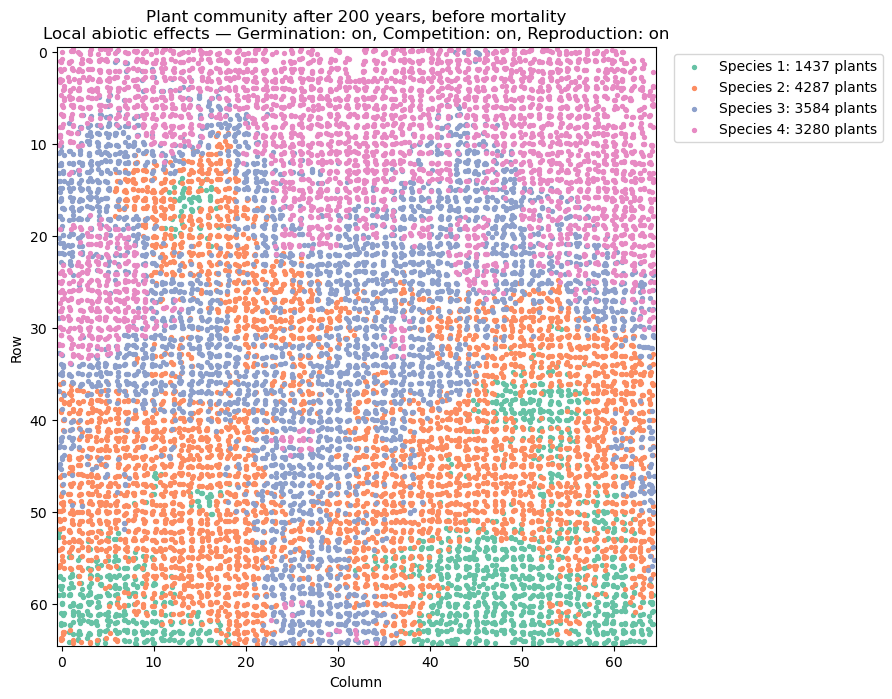

In [6]:
number_of_species, rows, columns = final_plants.shape
colors = plt.get_cmap("Set2").colors[:4]

# Display offsets separate plants occupying the same microsite.
display_random = np.random.default_rng(0)

figure, axis = plt.subplots(figsize=(9, 9))

for species in range(number_of_species):
    occupied_rows, occupied_columns = np.nonzero(final_plants[species])
    counts = final_plants[species, occupied_rows, occupied_columns]

    plant_rows = np.repeat(occupied_rows, counts)
    plant_columns = np.repeat(occupied_columns, counts)

    horizontal_offsets = display_random.uniform(
        -0.3, 0.3, size=len(plant_rows)
    )
    vertical_offsets = display_random.uniform(
        -0.3, 0.3, size=len(plant_rows)
    )

    axis.scatter(
        plant_columns + horizontal_offsets,
        plant_rows + vertical_offsets,
        s=8,
        color=colors[species],
        label=f"Species {species + 1}: {len(plant_rows)} plants",
    )

stage_names = ["Germination", "Competition", "Reproduction"]
treatment = ", ".join(
    f"{stage}: {'on' if enabled else 'off'}"
    for stage, enabled in zip(stage_names, abiotic_effects)
)

axis.set_title(
    f"Plant community after {years} years, before mortality\n"
    f"Local abiotic effects — {treatment}"
)
axis.set_xlabel("Column")
axis.set_ylabel("Row")
axis.set_xlim(-0.5, columns - 0.5)
axis.set_ylim(rows - 0.5, -0.5)
axis.set_aspect("equal")
axis.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

figure.tight_layout()
plt.show()

# Side by Side: Landscape and spatial structure distributions

## Loading Data

In [9]:
with np.load(simulation_file, allow_pickle=False) as data:
    final_plants = data["final_plants"]
    abiotic_effects = data["abiotic_effects"]
    landscape_files = data["landscape_files"]
    years = int(data["years"])

# Currently all stages use the same landscape.
landscape_file = project_folder / str(landscape_files[0])

with np.load(landscape_file, allow_pickle=False) as data:
    landscape = data["landscape"]

number_of_species, rows, columns = final_plants.shape
colors = colors = plt.get_cmap("Set2").colors[:4]

## Prepare Plant Coordinates

In [11]:
display_random = np.random.default_rng(0)
species_coordinates = []

for species in range(number_of_species):
    occupied_rows, occupied_columns = np.nonzero(final_plants[species])
    counts = final_plants[species, occupied_rows, occupied_columns]

    plant_rows = np.repeat(occupied_rows, counts)
    plant_columns = np.repeat(occupied_columns, counts)

    x = plant_columns + display_random.uniform(
        -0.3, 0.3, size=len(plant_columns)
    )
    y = plant_rows + display_random.uniform(
        -0.3, 0.3, size=len(plant_rows)
    )

    species_coordinates.append((x, y))

# Landscape besides the community

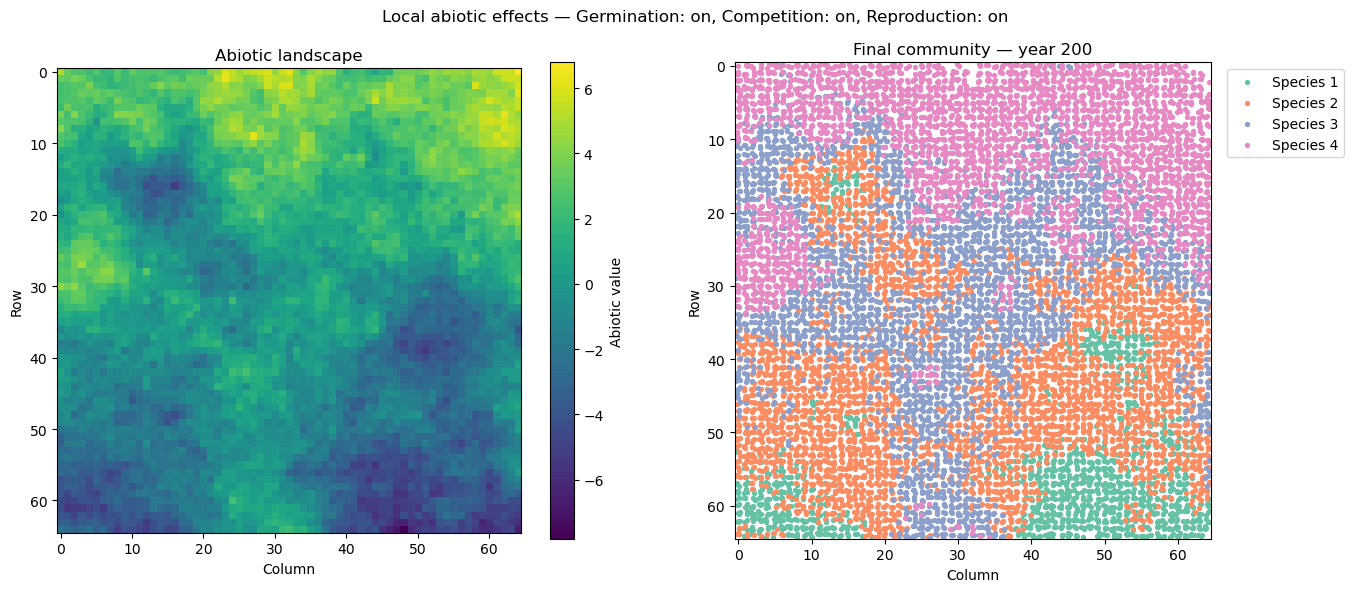

In [13]:
figure, axes = plt.subplots(figsize=(14, 6), ncols=2)

image = axes[0].imshow(
    landscape,
    cmap="viridis",
    origin="upper",
)
figure.colorbar(image, ax=axes[0], label="Abiotic value")
axes[0].set_title("Abiotic landscape")

for species, (x, y) in enumerate(species_coordinates):
    axes[1].scatter(
        x, y,
        s=8,
        color=colors[species],
        label=f"Species {species + 1}",
    )

axes[1].set_title(f"Final community — year {years}")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))

for axis in axes:
    axis.set_xlim(-0.5, columns - 0.5)
    axis.set_ylim(rows - 0.5, -0.5)
    axis.set_aspect("equal")
    axis.set_xlabel("Column")
    axis.set_ylabel("Row")

stage_names = ["Germination", "Competition", "Reproduction"]
treatment = ", ".join(
    f"{stage}: {'on' if enabled else 'off'}"
    for stage, enabled in zip(stage_names, abiotic_effects)
)
figure.suptitle(f"Local abiotic effects — {treatment}")

figure.tight_layout()
plt.show()

## Simulation 2:

Default Parameters:
- adjacent dispersal
- $\alpha_{jj} = \alpha_{ij} = 1$
- Abiotic effects
  - Germination: False
  - Competition: True
  - Reproduction: True 

In [15]:
simulation_file = (
    project_folder / "data/simulations/simulation_002.npz"
)

with np.load(simulation_file, allow_pickle=False) as data:
    final_plants = data["final_plants"]
    abiotic_effects = data["abiotic_effects"]
    landscape_files = data["landscape_files"]
    years = int(data["years"])

# Currently all stages use the same landscape.
landscape_file = project_folder / str(landscape_files[1])

with np.load(landscape_file, allow_pickle=False) as data:
    landscape = data["landscape"]

number_of_species, rows, columns = final_plants.shape
colors = colors = plt.get_cmap("Set2").colors[:4]

In [16]:
display_random = np.random.default_rng(0)
species_coordinates = []

for species in range(number_of_species):
    occupied_rows, occupied_columns = np.nonzero(final_plants[species])
    counts = final_plants[species, occupied_rows, occupied_columns]

    plant_rows = np.repeat(occupied_rows, counts)
    plant_columns = np.repeat(occupied_columns, counts)

    x = plant_columns + display_random.uniform(
        -0.3, 0.3, size=len(plant_columns)
    )
    y = plant_rows + display_random.uniform(
        -0.3, 0.3, size=len(plant_rows)
    )

    species_coordinates.append((x, y))

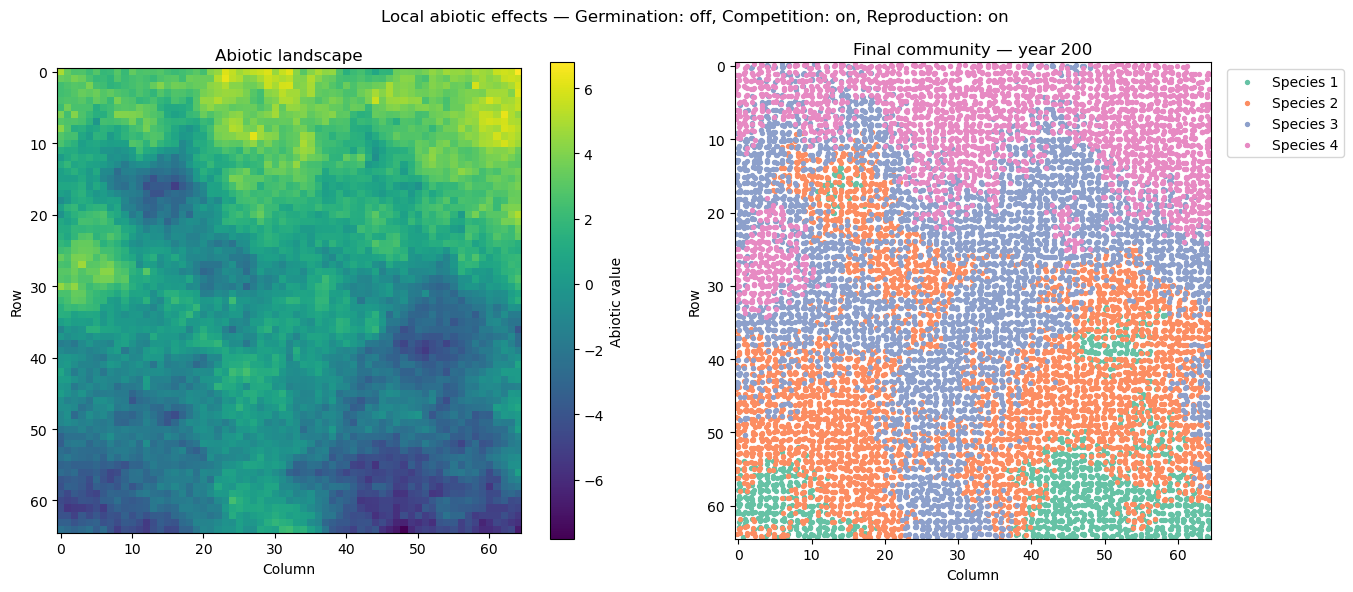

In [17]:
figure, axes = plt.subplots(figsize=(14, 6), ncols=2)

image = axes[0].imshow(
    landscape,
    cmap="viridis",
    origin="upper",
)
figure.colorbar(image, ax=axes[0], label="Abiotic value")
axes[0].set_title("Abiotic landscape")

for species, (x, y) in enumerate(species_coordinates):
    axes[1].scatter(
        x, y,
        s=8,
        color=colors[species],
        label=f"Species {species + 1}",
    )

axes[1].set_title(f"Final community — year {years}")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))

for axis in axes:
    axis.set_xlim(-0.5, columns - 0.5)
    axis.set_ylim(rows - 0.5, -0.5)
    axis.set_aspect("equal")
    axis.set_xlabel("Column")
    axis.set_ylabel("Row")

stage_names = ["Germination", "Competition", "Reproduction"]
treatment = ", ".join(
    f"{stage}: {'on' if enabled else 'off'}"
    for stage, enabled in zip(stage_names, abiotic_effects)
)
figure.suptitle(f"Local abiotic effects — {treatment}")

figure.tight_layout()
plt.show()

## Simulation 3

Default Parameters:
- adjacent dispersal
- $\alpha_{jj} = \alpha_{ij} = 1$
- Abiotic effects
  - Germination: False
  - Competition: False
  - Reproduction: False 

In [19]:
simulation_file = (
    project_folder / "data/simulations/simulation_003.npz"
)

with np.load(simulation_file, allow_pickle=False) as data:
    final_plants = data["final_plants"]
    abiotic_effects = data["abiotic_effects"]
    landscape_files = data["landscape_files"]
    years = int(data["years"])

# Currently all stages use the same landscape.
landscape_file = project_folder / str(landscape_files[2])

with np.load(landscape_file, allow_pickle=False) as data:
    landscape = data["landscape"]

number_of_species, rows, columns = final_plants.shape
colors = colors = plt.get_cmap("Set2").colors[:4]

In [20]:
display_random = np.random.default_rng(0)
species_coordinates = []

for species in range(number_of_species):
    occupied_rows, occupied_columns = np.nonzero(final_plants[species])
    counts = final_plants[species, occupied_rows, occupied_columns]

    plant_rows = np.repeat(occupied_rows, counts)
    plant_columns = np.repeat(occupied_columns, counts)

    x = plant_columns + display_random.uniform(
        -0.3, 0.3, size=len(plant_columns)
    )
    y = plant_rows + display_random.uniform(
        -0.3, 0.3, size=len(plant_rows)
    )

    species_coordinates.append((x, y))

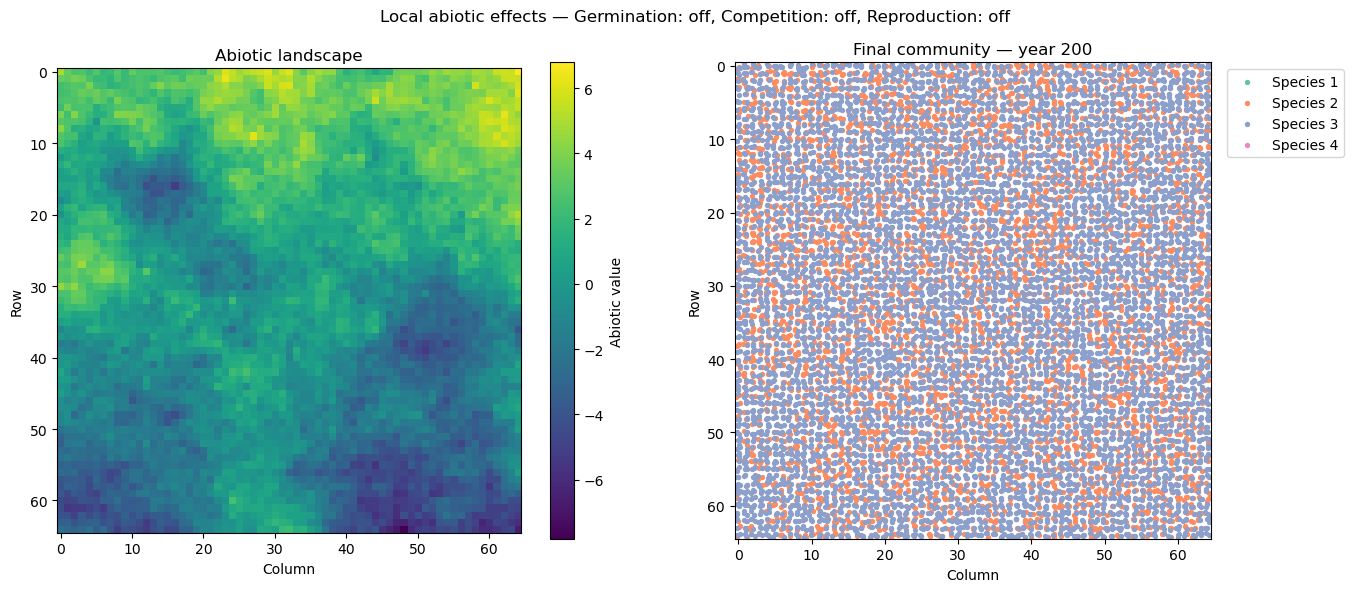

In [21]:
figure, axes = plt.subplots(figsize=(14, 6), ncols=2)

image = axes[0].imshow(
    landscape,
    cmap="viridis",
    origin="upper",
)
figure.colorbar(image, ax=axes[0], label="Abiotic value")
axes[0].set_title("Abiotic landscape")

for species, (x, y) in enumerate(species_coordinates):
    axes[1].scatter(
        x, y,
        s=8,
        color=colors[species],
        label=f"Species {species + 1}",
    )

axes[1].set_title(f"Final community — year {years}")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))

for axis in axes:
    axis.set_xlim(-0.5, columns - 0.5)
    axis.set_ylim(rows - 0.5, -0.5)
    axis.set_aspect("equal")
    axis.set_xlabel("Column")
    axis.set_ylabel("Row")

stage_names = ["Germination", "Competition", "Reproduction"]
treatment = ", ".join(
    f"{stage}: {'on' if enabled else 'off'}"
    for stage, enabled in zip(stage_names, abiotic_effects)
)
figure.suptitle(f"Local abiotic effects — {treatment}")

figure.tight_layout()
plt.show()